# Part 1 · 树模型的五组收益与因子暴露

**分析对象**是原版浅层梯度提升树独立锁定的 50 只股票。第一部分按树的次月收益预测分五组，比较实际收益、固定池等权和中证 500。第二部分展示逐月入选的因子、股票暴露，以及树模型对每个因子分配的预测贡献。

从 `artifacts/part1/tree/` 读取预测、实际收益和股票池。使用 Part 1 的 Python 3.11 内核从头运行。下文先按原模型重训，再对照导出的 116 个月预测。树模型每月重新训练，因此这一格耗时较长。

**本次结果。** 最高组比最低组平均每月多 2.68 个百分点，116 个月中有 68.1% 的月份胜出。中间组的收益排序不完全单调。下文对照五组收益、等权基准和因子贡献。

方法来源见 [Part 1 构建逻辑](../logic_readme.md)、[原版树模型 notebook](Part1_Return_Model_Tree.ipynb) 和 [共享因子筛选代码](../../src/sta4020_project/part1/forecasts.py)。

In [1]:
from math import comb
from pathlib import Path
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.optimize import brentq
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits

cwd = Path.cwd().resolve()
root = next(
    (path for path in (cwd, *cwd.parents) if (path / "src" / "sta4020_project").is_dir()),
    None,
)
if root is None:
    raise FileNotFoundError("从仓库根目录或其子目录启动 notebook。")
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

from sta4020_project.part1.features import TRAIN_MONTHS, ReturnFeatures
from sta4020_project.part1.forecasts import FDR_Q, SEED, rank_features, rank_ic, screen_factors
from sta4020_project.shared.contracts import read_wide

data_dir = root / "data"
part1_dir = root / "artifacts" / "part1" / "tree"
if not part1_dir.is_dir():
    raise FileNotFoundError("请先运行 Part1_Return_Model_Tree.ipynb 导出树模型的三份 CSV。")
expected = read_wide(part1_dir / "P1_Expected_Returns.csv")
realised = read_wide(part1_dir / "Actual_Returns.csv")
pool = pd.Index(pd.read_csv(part1_dir / "P1_Candidate_Universe.csv")["Asset"], name="asset")
forecast_months = expected.index.to_period("M")
outcome_months = forecast_months + 1

assert len(pool) == 50 and pool.is_unique
assert expected.columns.is_unique and realised.columns.is_unique
assert set(expected.columns) == set(realised.columns) == set(pool)
assert expected.index.is_month_end.all() and realised.index.is_month_end.all()
assert forecast_months.equals(pd.period_range(forecast_months[0], forecast_months[-1], freq="M", name="Date"))
assert realised.index.to_period("M").equals(outcome_months)
assert np.isfinite(expected.to_numpy()).all() and np.isfinite(realised.to_numpy()).all()
assert realised.ge(-1).all().all()
realised = realised.loc[:, expected.columns]

GROUPS = ["Q1", "Q2", "Q3", "Q4", "Q5"]
GROUP_LABELS = {
    "Q1": "Q1 Highest", "Q2": "Q2", "Q3": "Q3", "Q4": "Q4", "Q5": "Q5 Lowest",
}
COLORS = dict(zip(GROUPS, ["#00796b", "#62a48d", "#8e8e8e", "#cf8178", "#ae3d48"]))
STRESS_WINDOWS = {
    "2015 年股灾（6–8 月）": ("2015-06", "2015-08"),
    "2022 年下半年（7–12 月）": ("2022-07", "2022-12"),
}
FACTOR_LABELS = {
    "log_size": "Market cap",
    "log_amount_21d": "21-day traded value",
    "return_5d": "5-day return",
    "volatility_63d": "63-day volatility",
    "momentum_8w": "8-week momentum",
    "volatility_12w": "12-week volatility",
    "momentum_12_1m": "12–1 month momentum",
    "lagged_month_return": "Prior-month return",
    "return_month_to_signal": "Month-to-signal return",
    "pc1_market_beta": "First principal component",
    "pca_residual_volatility": "Principal component residual volatility",
}

print(f"{len(forecast_months)} 个实现月 × {len(pool)} 只股票 · {outcome_months[0]} 至 {outcome_months[-1]}")

116 个实现月 × 50 只股票 · 2015-01 至 2024-08


### 复用树模型的筛选与拟合

使用仓库的特征构建、排名变换和 Benjamini–Yekutieli 筛选。每月从 72 个已实现标签的训练月形成等月份权重，将当月的次月收益按第 1 和第 99 百分位缩尾并去截面均值。树按原 notebook 的参数拟合，预测时平移到历史共同收益水平。

以全零排名暴露为基准，用精确的 Shapley 值把拟合树的预测差分摊到入选因子。特征数较少，因此可以遍历所有子集并分摊交互效应。逐股票月校验重建预测、Shapley 分解与树模型导出的 CSV。

In [2]:
def tree_training_block(scores, target):
    valid = target.notna()
    measured_scores = scores.loc[valid]
    target = target.loc[valid]
    low, high = target.quantile([0.01, 0.99])
    response = target.clip(low, high).to_numpy()
    mean_response = response.mean()
    return {
        "ic": measured_scores.apply(rank_ic, target=target),
        "response_mean": mean_response,
        "design": measured_scores.fillna(0).to_numpy(dtype=np.float32),
        "response": (response - mean_response).astype(np.float32),
    }

def fit_tree(history, feature_positions):
    blocks = [record["design"][:, feature_positions] for record in history]
    design = np.concatenate(blocks)
    target = np.concatenate([record["response"] for record in history])
    observations_per_month = np.array([len(block) for block in blocks])
    per_row_weight = np.repeat(
        len(target) / (len(blocks) * observations_per_month), observations_per_month,
    )
    model = HistGradientBoostingRegressor(
        max_depth=3, max_leaf_nodes=8, max_iter=60, learning_rate=0.08,
        min_samples_leaf=250, l2_regularization=5.0, max_bins=32,
        early_stopping=False, random_state=SEED,
    )
    with threadpool_limits(limits=2):
        model.fit(design, target, sample_weight=per_row_weight)
    return model

def explain_relative_to_zero(model, values, expected_premium):
    # Evaluate every coalition with absent features set to zero.
    n_stocks, n_features = values.shape
    coalitions = np.arange(1 << n_features)
    bits = 1 << np.arange(n_features)
    included = (coalitions[:, None] & bits) != 0
    sizes = included.sum(axis=1)
    inputs = np.where(included[:, None, :], values, 0.0).reshape(-1, n_features)
    predictions = model.predict(inputs).reshape(len(coalitions), n_stocks)
    weights = np.array([
        1.0 / (n_features * comb(n_features - 1, size)) for size in range(n_features)
    ])
    contributions = np.empty((n_stocks, n_features))
    for column, bit in enumerate(bits):
        without = coalitions[~included[:, column]]
        marginal = predictions[without | bit] - predictions[without]
        contributions[:, column] = weights[sizes[without]] @ marginal
    zero_prediction = float(predictions[0, 0])
    np.testing.assert_allclose(zero_prediction + contributions.sum(axis=1),
                               expected_premium, atol=1e-10, rtol=0)
    return zero_prediction, contributions

features = ReturnFeatures(data_dir, forecast_months)
assets = pd.Index(expected.columns, name="asset")
forecast_dates = dict(zip(forecast_months, expected.index))
target_dates = dict(zip(forecast_months, realised.index))

training_stats = {}
rebuilt_rows = []
stock_rows = []
screening_rows = []
exposure_rows = []
history_months = pd.period_range(forecast_months[0] - TRAIN_MONTHS - 1, forecast_months[-1], freq="M")

with threadpool_limits(limits=1):
    for month in history_months:
        raw = features.at(month)
        scores = rank_features(raw)

        if month in forecast_dates:
            origin = forecast_dates[month]
            target = target_dates[month]
            signal_date = features.signal_close.loc[month]
            train_months = pd.period_range(month - TRAIN_MONTHS - 1, month - 2, freq="M")
            latest_label_close = features.last_close.loc[train_months[-1] + 1]
            assert latest_label_close < signal_date
            training = [training_stats[previous] for previous in train_months]
            ic_history = pd.DataFrame([record["ic"] for record in training], index=train_months)
            selected, audit = screen_factors(ic_history)
            fresh = pd.Series(assets.isin(scores.index), index=assets, name="fresh_signal")
            common_level = float(np.mean([record["response_mean"] for record in training]))
            model_base = pd.Series(common_level, index=assets)

            rank_exposure = scores.reindex(assets)[selected]
            model_exposure = rank_exposure.fillna(0.0).where(fresh, axis=0)
            contribution = pd.DataFrame(np.nan, index=assets, columns=selected)
            if selected:
                model = fit_tree(training, scores.columns.get_indexer(selected))
                all_scores = scores[selected].fillna(0.0)
                premium = pd.Series(model.predict(all_scores.to_numpy()), index=scores.index)
                live = assets[fresh]
                zero_prediction, explained = explain_relative_to_zero(
                    model, model_exposure.loc[live].to_numpy(), premium.loc[live].to_numpy(),
                )
                model_base.loc[live] = common_level + (zero_prediction - premium.mean())
                contribution.loc[live] = explained

            rebuilt_rows.append(model_base + contribution.sum(axis=1))
            date_fields = {"formation_date": origin, "signal_date": signal_date, "realization_date": target}
            stock_rows.append(pd.DataFrame({
                **date_fields,
                "fresh_signal": fresh,
                "prediction_base": model_base,
                "predicted_return": expected.loc[origin].reindex(assets),
                "realized_return": realised.loc[target].reindex(assets),
            }).rename_axis("asset").reset_index())

            screening_rows.append(audit.rename_axis("factor").reset_index().assign(
                **date_fields, latest_label_close=latest_label_close,
                selected=lambda frame: frame["factor"].isin(selected),
            ))
            raw_selected = raw.reindex(assets)[selected]
            for factor in selected:
                exposure_rows.append(pd.DataFrame({
                    **date_fields,
                    "factor": factor,
                    "raw_feature": raw_selected[factor],
                    "rank_exposure": rank_exposure[factor],
                    "model_exposure": model_exposure[factor],
                    "feature_imputed": fresh & rank_exposure[factor].isna(),
                    "forecast_contribution": contribution[factor],
                }).rename_axis("asset").reset_index())

        if month <= forecast_months[-1] - 2:
            next_return = features.returns.loc[month + 1].reindex(scores.index)
            training_stats[month] = tree_training_block(scores, next_return)

rebuilt = pd.DataFrame(rebuilt_rows, index=expected.index)
np.testing.assert_allclose(rebuilt.to_numpy(), expected.to_numpy(), atol=1e-9, rtol=0)
stock_panel = pd.concat(stock_rows, ignore_index=True)
factor_screen = pd.concat(screening_rows, ignore_index=True)
selected_factor_exposures = pd.concat(exposure_rows, ignore_index=True)
assert not selected_factor_exposures.duplicated(["formation_date", "asset", "factor"]).any()
assert len(factor_screen) == len(expected) * len(FACTOR_LABELS)
max_prediction_error = (rebuilt - expected).abs().to_numpy().max()
print(f"重建了 {stock_panel.shape[0]:,} 条树模型股票月预测，最大绝对差 {max_prediction_error:.2e}。")

重建了 5,800 条树模型股票月预测，最大绝对差 1.05e-16。


## 1. 按预测收益分五组

每个信号月把 50 只股票按树模型交付预测从高到低排列。同分按股票代码升序，Q1 到 Q5 各 10 只，Q1 最高。组内对下一月实际收益取等权平均。分组收益是**未计费用和成交约束的排序诊断**。另外复刻原版树模型 notebook 的固定池等权净值（每只有效信号股票目标权重 2%、缺报价或不可交易时冻结、买卖各 20 个基点、现金赚取无风险收益），作为树池的组合基准。中证 500 使用价格指数。

完整 50 只的分组保留了回退到共同均值的预测。另算只用当月有效信号股票的五组、Rank IC 和最高减最低组差，检查结果对回退值的敏感性。有效信号口径的组大小会随月份变化。

In [3]:
def rank_and_group(panel):
    ranked = panel.sort_values(
        ["formation_date", "predicted_return", "asset"], ascending=[True, False, True],
    ).copy()
    by_month = ranked.groupby("formation_date", sort=False)
    ranked["score_rank"] = by_month.cumcount() + 1
    month_size = by_month["asset"].transform("size")
    assert month_size.ge(len(GROUPS)).all()
    group_number = ((ranked["score_rank"] - 1) * len(GROUPS)) // month_size
    ranked["quintile"] = group_number.map(dict(enumerate(GROUPS)))
    return ranked

def group_returns(panel):
    return panel.groupby(["realization_date", "quintile"])["realized_return"].mean().unstack()[GROUPS]

stock_panel = rank_and_group(stock_panel)
fresh_panel = rank_and_group(stock_panel.loc[stock_panel["fresh_signal"]])
quintile_monthly = group_returns(stock_panel)
fresh_quintile_monthly = group_returns(fresh_panel)
assert stock_panel.groupby(["formation_date", "quintile"]).size().eq(10).all()

pool_gross = realised.mean(axis=1).rename("Tree pool gross equal weight")
np.testing.assert_allclose(quintile_monthly.mean(axis=1), pool_gross, atol=1e-14, rtol=0)
index_close = pd.read_pickle(data_dir / "zz500.pk")["close"].sort_index()
index_months = pd.period_range(forecast_months[0], outcome_months[-1], freq="M")
index_prices = index_close.reindex(features.last_close.loc[index_months].to_numpy())
assert np.isfinite(index_prices).all() and index_prices.gt(0).all()
csi500 = (
    index_prices.pct_change(fill_method=None).iloc[1:]
    .set_axis(realised.index)
    .rename("CSI 500 price index")
)

def fixed_pool_equal_weight_net():
    risk_free = pd.read_csv(data_dir / "risk_free.csv", index_col="date", parse_dates=True)["RF"]
    daily_rf = risk_free.reindex(features.prices.index)
    monthly_rf = (1 + daily_rf).groupby(daily_rf.index.to_period("M")).prod(min_count=1) - 1
    assert monthly_rf.reindex(outcome_months).notna().all()
    signal_flags = stock_panel.pivot(index="formation_date", columns="asset", values="fresh_signal")
    pretrade = np.zeros(len(assets))
    net_returns = []
    fee_rate = 0.002
    for month, origin in forecast_dates.items():
        trade_date = features.last_close.loc[month]
        blocked = assets.isin(features.untradable.get(trade_date, ()))
        frozen = features.prices.loc[trade_date, assets].isna().to_numpy() | blocked
        blacklisted = assets.isin(features.blacklist.get(trade_date, ()))
        desired = (signal_flags.loc[origin, assets].to_numpy() & ~blacklisted & ~frozen) / len(assets)
        frozen_value = pretrade[frozen].sum()
        target_total = desired.sum()

        def positions_after_fee(fee):
            available = max(0.0, 1.0 - frozen_value - fee)
            scale = min(1.0, available / target_total) if target_total else 0.0
            return np.where(frozen, pretrade, desired * scale)

        fee = brentq(
            lambda fee: fee - fee_rate * np.abs(positions_after_fee(fee) - pretrade).sum(),
            0.0, 2 * fee_rate + 1e-10,
        )
        weights = positions_after_fee(fee) / (1.0 - fee)
        cash_weight = max(0.0, 1.0 - weights.sum())
        actual = realised.loc[target_dates[month], assets].to_numpy()
        gross = weights @ actual + cash_weight * monthly_rf.loc[month + 1]
        net_returns.append((1.0 - fee) * (1.0 + gross) - 1.0)
        pretrade = weights * (1.0 + actual) / (1.0 + gross)
    return pd.Series(net_returns, index=realised.index, name="Tree pool net equal weight")

pool_net = fixed_pool_equal_weight_net()
monthly_benchmarks = pd.concat([pool_gross, pool_net, csi500], axis=1)
spread = (quintile_monthly["Q1"] - quintile_monthly["Q5"]).rename("Q1 minus Q5")
fresh_spread = (fresh_quintile_monthly["Q1"] - fresh_quintile_monthly["Q5"]).rename("Fresh-signal Q1 minus Q5")

def monthly_rank_ic(panel):
    return pd.Series({
        date: spearmanr(group["predicted_return"], group["realized_return"]).statistic
        for date, group in panel.groupby("realization_date")
    })

def compound(returns):
    return (1.0 + returns).prod() - 1.0

def drawdown(returns):
    wealth = (1.0 + returns).cumprod()
    return (wealth / wealth.cummax().clip(lower=1.0) - 1.0).min()

def return_table(returns):
    return pd.DataFrame({
        "Mean monthly": returns.mean(),
        "Annualized compound": (1 + compound(returns)) ** (12 / len(returns)) - 1,
        "Annualized volatility": returns.std() * np.sqrt(12),
        "Maximum drawdown": drawdown(returns),
    })

all_returns = quintile_monthly.join(monthly_benchmarks)
quintile_summary = return_table(all_returns)
ordering_summary = pd.DataFrame({
    "Mean monthly rank IC": [monthly_rank_ic(stock_panel).mean(), monthly_rank_ic(fresh_panel).mean()],
    "Mean monthly Q1 minus Q5": [spread.mean(), fresh_spread.mean()],
    "Months Q1 beat Q5": [spread.gt(0).mean(), fresh_spread.gt(0).mean()],
}, index=["All 50 stocks", "Fresh signals only"])

display(quintile_summary.style.format("{:.2%}"))
display(ordering_summary.style.format({
    "Mean monthly rank IC": "{:.4f}", "Mean monthly Q1 minus Q5": "{:+.2%}", "Months Q1 beat Q5": "{:.1%}",
}))

stress_rows = {}
for window, (start, end) in STRESS_WINDOWS.items():
    window_returns = all_returns.loc[start:end]
    stress_rows[window] = pd.concat({
        "Period return": compound(window_returns),
        "Maximum drawdown": drawdown(window_returns),
    }, axis=1)
stress_returns = pd.concat(stress_rows, axis=1)
window_spread = pd.DataFrame([
    {
        "Window": window,
        "Months": len(spread.loc[start:end]),
        "Mean monthly Q1 minus Q5": spread.loc[start:end].mean(),
        "Mean monthly Q1 minus Q5, fresh signals": fresh_spread.loc[start:end].mean(),
        "Mean monthly pool gross minus CSI 500": (pool_gross - csi500).loc[start:end].mean(),
        "Share of fallback forecasts": 1.0 - stock_panel.set_index("realization_date").sort_index()
            .loc[start:end, "fresh_signal"].mean(),
    }
    for window, (start, end) in STRESS_WINDOWS.items()
]).set_index("Window")
display(stress_returns.style.format("{:.2%}"))
display(window_spread.style.format({
    column: "{:.2%}" for column in window_spread if column != "Months"
}))

,Mean monthly,Annualized compound,Annualized volatility,Maximum drawdown
Q1,2.16%,20.50%,39.29%,-49.17%
Q2,1.78%,16.33%,36.50%,-46.57%
Q3,0.79%,3.58%,35.11%,-55.35%
Q4,0.93%,7.09%,30.16%,-53.62%
Q5,-0.53%,-11.91%,35.72%,-85.77%
Tree pool gross equal weight,1.03%,7.78%,31.88%,-51.71%
Tree pool net equal weight,0.97%,7.34%,30.87%,-52.47%
CSI 500 price index,0.13%,-1.41%,24.46%,-58.18%


,Mean monthly rank IC,Mean monthly Q1 minus Q5,Months Q1 beat Q5
All 50 stocks,0.1259,+2.68%,68.1%
Fresh signals only,0.1419,+2.72%,71.6%


,Months,Mean monthly Q1 minus Q5,"Mean monthly Q1 minus Q5, fresh signals",Mean monthly pool gross minus CSI 500,Share of fallback forecasts
Window,,,,,
2015 年股灾（6–8 月）,3,-2.07%,5.32%,-0.03%,24.67%
2022 年下半年（7–12 月）,6,4.70%,4.28%,1.90%,13.00%


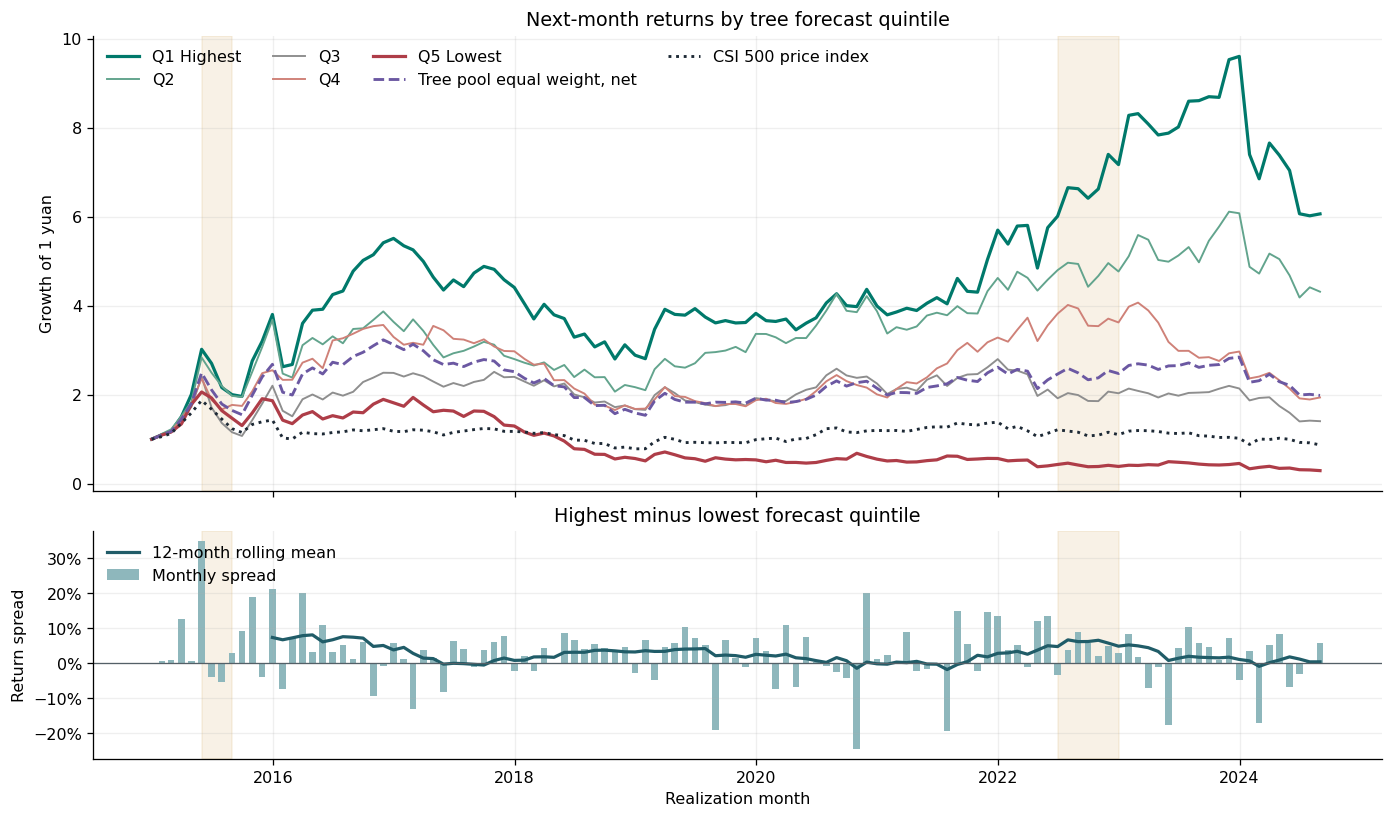

quintile,Q1,Q2,Q3,Q4,Q5
realization_date,,,,,
2024-01-31 00:00:00,-22.96%,-19.80%,-12.51%,-20.32%,-26.50%
2024-02-29 00:00:00,-7.38%,-3.13%,2.94%,1.72%,9.62%
2024-03-31 00:00:00,11.73%,9.52%,0.79%,3.49%,6.50%
2024-04-30 00:00:00,-3.58%,-2.40%,-10.09%,-6.76%,-11.83%
2024-05-31 00:00:00,-4.64%,-7.26%,-8.68%,-7.98%,2.18%
2024-06-30 00:00:00,-13.83%,-10.61%,-12.23%,-10.31%,-10.73%
2024-07-31 00:00:00,-0.76%,5.49%,1.26%,-1.30%,-1.51%
2024-08-31 00:00:00,0.72%,-2.23%,-0.87%,2.41%,-5.08%


In [4]:
plt.rcParams.update({
    "figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.20, "font.size": 10,
})
initial = expected.index[0]
wealth = pd.concat([
    pd.DataFrame(1.0, index=[initial], columns=all_returns.columns),
    (1.0 + all_returns).cumprod(),
])

fig, (path_ax, spread_ax) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout="constrained",
                                         gridspec_kw={"height_ratios": [2, 1]})
for name in GROUPS:
    path_ax.plot(wealth.index, wealth[name], color=COLORS[name], label=GROUP_LABELS[name],
                 linewidth=2.0 if name in ("Q1", "Q5") else 1.2)
path_ax.plot(wealth.index, wealth[pool_net.name], color="#6b58a2", linestyle="--",
             linewidth=1.8, label="Tree pool equal weight, net")
path_ax.plot(wealth.index, wealth[csi500.name], color="#1d2935", linestyle=":",
             linewidth=1.8, label=csi500.name)
path_ax.set(title="Next-month returns by tree forecast quintile", ylabel="Growth of 1 yuan")
path_ax.legend(ncols=4, loc="upper left", frameon=False)
spread_ax.bar(spread.index, spread, width=20, color="#8eb7bc", label="Monthly spread")
spread_ax.plot(spread.rolling(12).mean(), color="#205c68", linewidth=2, label="12-month rolling mean")
spread_ax.axhline(0, color="#546067", linewidth=0.8)
spread_ax.set(title="Highest minus lowest forecast quintile", ylabel="Return spread", xlabel="Realization month")
spread_ax.yaxis.set_major_formatter(PercentFormatter(1.0))
spread_ax.legend(loc="upper left", frameon=False)
for (start, end) in STRESS_WINDOWS.values():
    for ax in (path_ax, spread_ax):
        ax.axvspan(pd.Period(start).start_time, pd.Period(end).end_time,
                   color="#d8b16c", alpha=0.17, zorder=0)
spread_ax.xaxis.set_major_locator(mdates.YearLocator(2))
spread_ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

display(quintile_monthly.tail(8).style.format("{:.2%}"))

## 2. 逐月展示入选因子的暴露

- **原始特征（`raw_feature`）**是共享特征构建器的数值，个别变量已先取对数。
- **排名暴露（`rank_exposure`）**是当月宽截面的居中百分位分数再乘以 √12。**模型暴露（`model_exposure`）**是树的实际输入。有信号的股票在单项特征缺失时用零填补。整只股票无信号时，暴露和贡献保留缺失，预测用历史共同收益水平回退。
- **预测贡献（`forecast_contribution`）**是相对全零暴露参考点的 Shapley 值，单位是次月预测收益的小数。逐个因子计算不同加入顺序下的预测变化并取加权平均，因子间的交互效应也会分摊。贡献大小和方向会随股票及月份改变。预测基准加各因子贡献之和应精确还原树的预测。

因子没有入选的月不产生暴露记录。`factor_screen` 仍保留每个候选的筛选状态、p-value 和 q-value。

In [5]:
stock_factor_exposures = selected_factor_exposures.merge(
    stock_panel[["formation_date", "asset", "quintile", "score_rank", "fresh_signal",
                 "predicted_return", "realized_return"]],
    on=["formation_date", "asset"], how="left", validate="many_to_one",
).merge(
    factor_screen[["formation_date", "factor", "q_value", "mean_rank_ic"]],
    on=["formation_date", "factor"], how="left", validate="many_to_one",
)
assert stock_factor_exposures["quintile"].notna().all()
assert stock_factor_exposures["q_value"].le(FDR_Q).all()
assert stock_factor_exposures.loc[~stock_factor_exposures["fresh_signal"], "model_exposure"].isna().all()

stock_totals = stock_factor_exposures.groupby(["formation_date", "asset"])["forecast_contribution"].sum()
decomposition = stock_panel.set_index(["formation_date", "asset"])
reconstructed = decomposition["prediction_base"] + stock_totals.reindex(decomposition.index, fill_value=0)
np.testing.assert_allclose(reconstructed, decomposition["predicted_return"], atol=1e-9, rtol=0)

quintile_factor_exposures = stock_factor_exposures.groupby(
    ["formation_date", "realization_date", "quintile", "factor"], as_index=False,
).agg(
    stock_count=("asset", "size"),
    fresh_stock_count=("fresh_signal", "sum"),
    observed_exposure_count=("rank_exposure", "count"),
    imputed_count=("feature_imputed", "sum"),
    mean_model_exposure=("model_exposure", "mean"),
    mean_fresh_contribution=("forecast_contribution", "mean"),
    contribution_sum=("forecast_contribution", "sum"),
    q_value=("q_value", "first"),
)
# The denominator is the full group of ten. Fallback predictions have no factor component.
quintile_factor_exposures["group_forecast_contribution"] = (
    quintile_factor_exposures.pop("contribution_sum") / quintile_factor_exposures["stock_count"]
)
group_base = stock_panel.groupby(["realization_date", "quintile"])["prediction_base"].mean().unstack()
group_prediction = stock_panel.groupby(["realization_date", "quintile"])["predicted_return"].mean().unstack()
group_contribution = quintile_factor_exposures.groupby(
    ["realization_date", "quintile"],
)["group_forecast_contribution"].sum().unstack().reindex_like(group_base).fillna(0)
np.testing.assert_allclose(group_base + group_contribution, group_prediction, atol=1e-9, rtol=0)

exposure_spread = quintile_factor_exposures.pivot(
    index=["realization_date", "factor"], columns="quintile", values="mean_model_exposure",
).eval("Q1 - Q5").unstack().reindex(realised.index)
contribution_spread = quintile_factor_exposures.pivot(
    index=["realization_date", "factor"], columns="quintile", values="group_forecast_contribution",
).eval("Q1 - Q5").unstack().reindex(realised.index)
np.testing.assert_allclose(
    contribution_spread.sum(axis=1) + group_base["Q1"] - group_base["Q5"],
    group_prediction["Q1"] - group_prediction["Q5"], atol=1e-9, rtol=0,
)

selection_counts = factor_screen.groupby("factor")["selected"].sum().sort_values(ascending=False)
print(f"{len(stock_factor_exposures):,} 条股票 × 入选因子 × 月度记录。")
print("股票级和五组级的预测贡献均已与交付预测逐项对上。")
display(selection_counts.to_frame("Selected months"))

39,600 条股票 × 入选因子 × 月度记录。
股票级和五组级的预测贡献均已与交付预测逐项对上。


,Selected months
factor,
log_amount_21d,116
pca_residual_volatility,116
return_month_to_signal,116
volatility_63d,115
momentum_8w,113
volatility_12w,101
return_5d,44
log_size,36
lagged_month_return,20


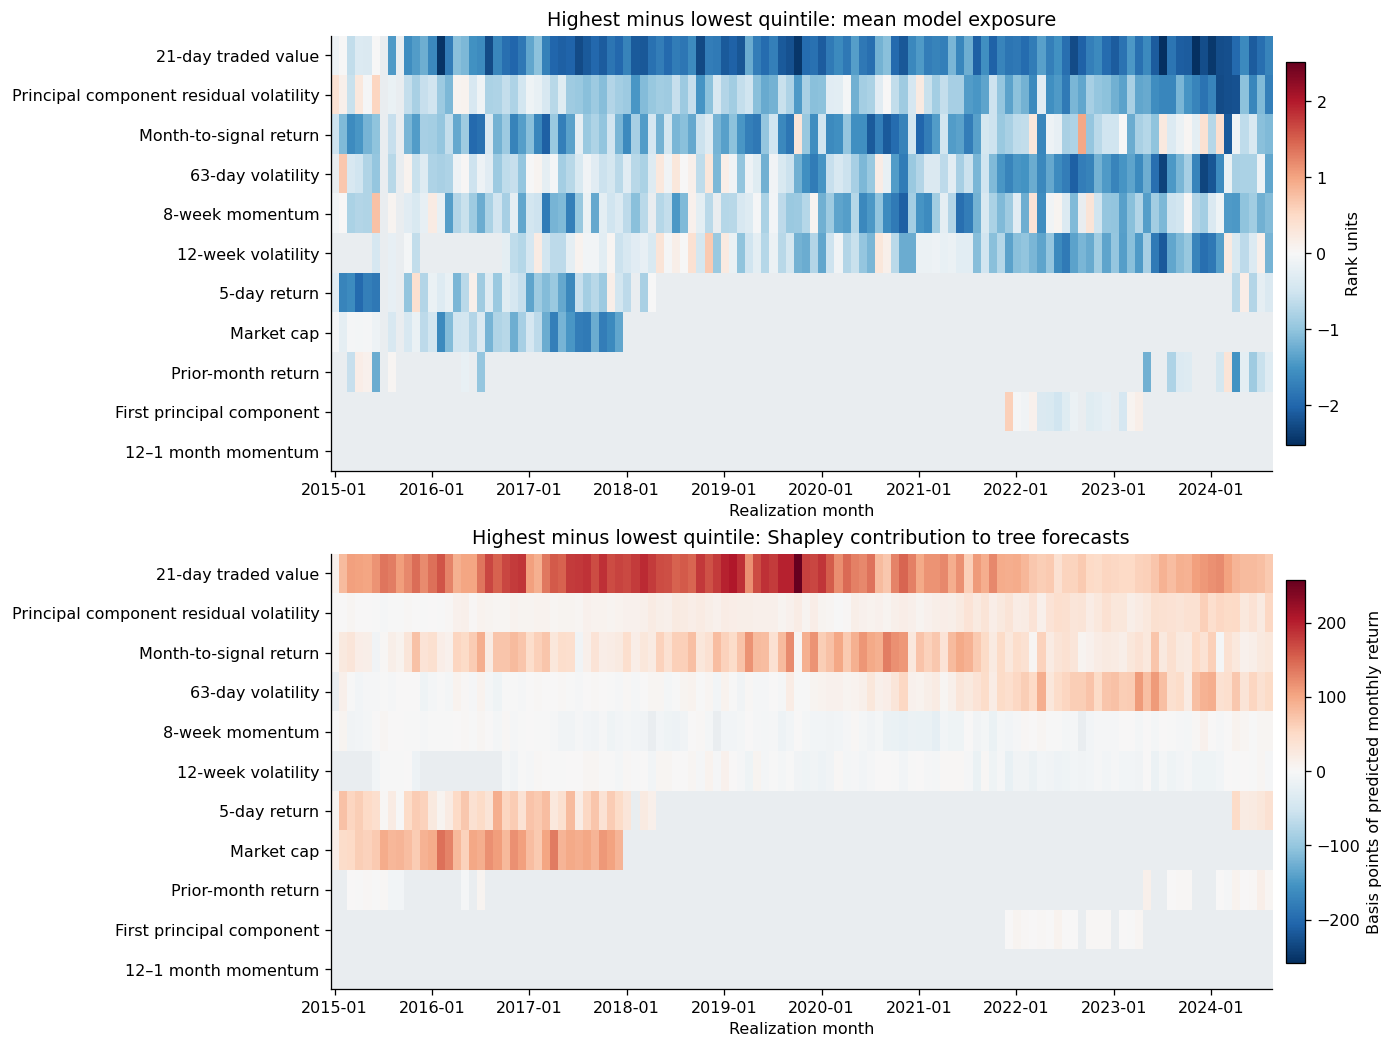

In [6]:
def plot_factor_heatmap(ax, frame, title, unit):
    order = selection_counts.index
    matrix = frame.reindex(columns=order).T
    values = matrix.to_numpy()
    limit = max(1e-8, np.nanmax(np.abs(values)))
    palette = plt.get_cmap("RdBu_r").copy()
    palette.set_bad("#e9edf0")
    chart = ax.imshow(np.ma.masked_invalid(values), aspect="auto", interpolation="nearest",
                      cmap=palette, norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit))
    ax.set(yticks=np.arange(len(order)), yticklabels=[FACTOR_LABELS[name] for name in order],
           title=title)
    ax.grid(False)
    ax.figure.colorbar(chart, ax=ax, label=unit, shrink=0.88, pad=0.015)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), layout="constrained")
plot_factor_heatmap(ax1, exposure_spread, "Highest minus lowest quintile: mean model exposure", "Rank units")
plot_factor_heatmap(ax2, contribution_spread * 1e4, "Highest minus lowest quintile: Shapley contribution to tree forecasts",
                    "Basis points of predicted monthly return")
ticks = np.arange(0, len(realised), 12)
labels = realised.index[ticks].strftime("%Y-%m")
for ax in (ax1, ax2):
    ax.set(xticks=ticks, xticklabels=labels, xlabel="Realization month")
plt.show()

热图按**实现月**显示，所有暴露和树模型预测取自上一月的信号日。灰色表示该因子当月未入选，或该组没有可汇总的信号。

下一格可以切换查看月份、股票组以及展示的是排名暴露还是预测贡献。设置 `DETAIL_GROUP = None` 可显示完整 50 只。另把两个压力窗口内的组间预测差按因子汇总为基点，方便定位具体月份和股票。

In [7]:
DETAIL_MONTH = "2015-07"  # 实现月。用于选组的信号产生于上月。
DETAIL_GROUP = "Q1"       # 也可以设为 Q2 到 Q5，或 None 查看全部 50 只。
DETAIL_VALUE = "model_exposure"  # 或 rank_exposure、raw_feature、forecast_contribution。

detail_date = pd.Period(DETAIL_MONTH, freq="M").end_time.normalize()
detail_factors = factor_screen.loc[
    factor_screen["realization_date"].eq(detail_date) & factor_screen["selected"],
    ["factor", "months", "mean_rank_ic", "p_value", "q_value"],
].sort_values("q_value").set_index("factor")
if detail_factors.empty:
    raise ValueError(f"{DETAIL_MONTH} 无入选因子，或超出样本外月份。")
display(detail_factors.style.format("{:.4f}", subset=detail_factors.columns.difference(["months"])))

detail = stock_factor_exposures.loc[stock_factor_exposures["realization_date"].eq(detail_date)]
if DETAIL_GROUP is not None:
    detail = detail.loc[detail["quintile"].eq(DETAIL_GROUP)]
detail_values = detail.pivot(
    index=["score_rank", "asset", "quintile", "fresh_signal"], columns="factor", values=DETAIL_VALUE,
).sort_index().reindex(columns=detail_factors.index)
display(detail_values.style.format("{:.4f}", na_rep="—"))

window_factor_contribution = pd.DataFrame({
    window: (contribution_spread.loc[start:end].fillna(0.0).mean() * 1e4)
    for window, (start, end) in STRESS_WINDOWS.items()
}).reindex(selection_counts.index)
window_factor_contribution["Selected months (full sample)"] = selection_counts
display(window_factor_contribution.style.format(
    "{:+.2f}", subset=list(STRESS_WINDOWS), na_rep="—",
))

,months,mean_rank_ic,p_value,q_value
factor,,,,
log_size,72,-0.0773,0.0005,0.0033
log_amount_21d,72,-0.1239,0.0005,0.0033
return_5d,72,-0.0445,0.0005,0.0033
momentum_8w,72,-0.0620,0.0005,0.0033
return_month_to_signal,72,-0.0622,0.0005,0.0033
volatility_63d,72,-0.0470,0.0010,0.0055
pca_residual_volatility,72,-0.0329,0.0050,0.0237
lagged_month_return,72,-0.0399,0.0140,0.0581
volatility_12w,72,-0.0318,0.0170,0.0627


,,,factor,log_size,log_amount_21d,return_5d,momentum_8w,return_month_to_signal,volatility_63d,pca_residual_volatility,lagged_month_return,volatility_12w
score_rank,asset,quintile,fresh_signal,,,,,,,,,
1,600605.SH,Q1,True,-1.6723,-1.5461,-0.3043,0.9644,-0.1113,0.0536,0.1151,0.8866,-0.5053
2,002352.SZ,Q1,True,-1.6437,-1.6908,-0.2166,1.1602,-0.6217,-0.5679,0.7930,1.2955,0.2593
3,300138.SZ,Q1,True,-1.6538,-1.5293,-0.4384,0.3132,-0.7031,0.5095,-1.5825,0.7806,0.9378
4,300260.SZ,Q1,True,-1.6521,-1.6976,-1.2687,1.2983,0.3194,0.9498,0.4567,1.0599,-0.8619
5,002213.SZ,Q1,True,-1.6387,-1.5933,-0.0808,0.2823,-0.3303,0.0000,0.3912,0.4946,0.0000
6,300176.SZ,Q1,True,-1.5848,-1.6219,-1.3908,0.8696,-1.4488,1.0472,-1.2355,1.5159,1.1161
7,300062.SZ,Q1,True,-1.6471,-1.7060,0.2544,0.0000,-0.2778,1.1349,-1.1577,0.8328,0.0000
8,600768.SH,Q1,True,-1.6690,-1.3880,-0.4281,1.3560,0.5131,0.4725,-1.1771,0.9994,1.1858
9,300211.SZ,Q1,True,-1.3241,-1.6420,-1.4939,1.2097,-1.6551,0.9868,-0.2248,1.6488,1.4441


,2015 年股灾（6–8 月）,2022 年下半年（7–12 月）,Selected months (full sample)
factor,,,
log_amount_21d,+128.90,+55.44,116
pca_residual_volatility,-1.73,+31.79,116
return_month_to_signal,+2.91,+21.63,116
volatility_63d,-2.18,+62.70,115
momentum_8w,+1.68,-3.41,113
volatility_12w,-2.53,-7.43,101
return_5d,+22.34,+0.00,44
log_size,+82.73,+0.00,36
lagged_month_return,-1.65,+0.00,20


### 树模型固定池的波动和回撤

上面的图表和下文的压力窗口说明使用树模型的固定股票池。月收益方差拆解用 50 只股票的毛等权收益，净等权表现则沿用原版树模型的实际回测口径。Shapley 贡献说明模型为何给股票打高分，实际下跌的说明来自实现收益。

**全样本（2015 年 1 月至 2024 年 8 月）**：树池净等权的年化波动为 **30.87%**，中证 500 价格指数为 **24.46%**。个股之间的协方差项占树池毛等权月收益方差约 **93.7%**，说明池内股票同步涨跌的影响很大。最高组减最低组的月均收益差为 **+2.68 个百分点**，在 **68.1%** 的月份为正。

以下日期均为**收益实现月**。月收益从上月末到当月末计算，区间累计按月复利。

#### 2015 年股灾（2015 年 6–8 月）

| 实现月 | 树池净等权 | 中证 500 价格指数 | 树池 − 指数（百分点） |
| --- | ---: | ---: | ---: |
| 2015-06 | −15.30% | −10.64% | −4.66 |
| 2015-07 | −15.14% | −13.24% | −1.90 |
| 2015-08 | −8.01% | −14.83% | +6.81 |
| **区间累计** | **−33.88%** | **−33.97%** | **+0.09** |

6 月和 7 月树池净等权跌得更深，分别落后指数 **4.66** 和 **1.90 个百分点**。8 月树池少跌 **6.81 个百分点**，三个月累计跌幅最终接近。同期五个预测组都累计下跌，6–8 月分别有 **39、38、34 只**股票下跌。

#### 2022 年下半年（2022 年 7–12 月）

| 实现月 | 树池净等权 | 中证 500 价格指数 | 树池 − 指数（百分点） |
| --- | ---: | ---: | ---: |
| 2022-07 | +5.20% | −2.48% | +7.68 |
| 2022-08 | −3.95% | −2.20% | −1.75 |
| 2022-09 | −6.22% | −7.18% | +0.95 |
| 2022-10 | +1.86% | +1.63% | +0.23 |
| 2022-11 | +6.92% | +6.01% | +0.91 |
| 2022-12 | −2.63% | −4.74% | +2.11 |
| **区间累计** | **+0.47%** | **−9.14%** | **+9.61** |

树池的相对优势主要来自 **7 月**，当月树池涨 **5.20%**，指数跌 **2.48%**。两者在 8–9 月都回撤，9 月有 **41 只**树池股票下跌。到 9 月末，树池和指数的窗口内最大回撤分别为 **−9.93%** 和 **−11.47%**。10–11 月树池继续反弹，半年累计收益领先 **9.61 个百分点**。

**因子贡献的口径。** 2015 年股灾期间，21 日成交额对最高组与最低组的月度**预测**差平均贡献 **+128.9 个基点**。2022 年下半年，这项贡献绝对值最大的是 63 日波动（**+62.7 个基点/月**）。这些数字解释树把哪些股票排得更高。上面的指数对照使用实现收益。

后续可以直接用 `stock_factor_exposures`、`quintile_factor_exposures`、`factor_screen` 和 `quintile_monthly`。启用下方的 `EXPORT_CSV` 后，树模型明细会导出到 `.cache/part1-analysis/tree/`。

In [9]:
EXPORT_CSV = True
if EXPORT_CSV:
    export_dir = root / ".cache" / "part1-analysis" / "tree"
    export_dir.mkdir(parents=True, exist_ok=True)
    for name, frame in {
        "stock_monthly": stock_panel,
        "factor_screen": factor_screen,
        "stock_factor_exposures": stock_factor_exposures,
        "quintile_factor_exposures": quintile_factor_exposures,
    }.items():
        frame.to_csv(export_dir / f"{name}.csv", index=False)
    quintile_monthly.join(monthly_benchmarks).join(spread).join(fresh_spread).to_csv(
        export_dir / "quintile_monthly_returns.csv", index_label="realization_date",
    )
    print(export_dir)

.cache/part1-analysis/tree
